In [1]:
import pandas as pd

print("Instamart AI 360 - EDA Started!")

Instamart AI 360 - EDA Started!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
customers = pd.read_csv("../data/synthetic/customers.csv")
products = pd.read_csv("../data/synthetic/products.csv")
orders = pd.read_csv("../data/synthetic/orders.csv")
order_items = pd.read_csv("../data/synthetic/order_items.csv")
tickets = pd.read_csv("../data/synthetic/support_tickets.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("CUSTOMERS DATA")
display(customers.head())

print("ORDERS DATA")
display(orders.head())

print("PRODUCTS DATA")
display(products.head())

print("SUPPORT TICKETS DATA")
display(tickets.head())


CUSTOMERS DATA


,customer_id,name,age,city,signup_date,membership
0,CUST0001,Customer_0001,22,Chennai,2026-01-12,Regular
1,CUST0002,Customer_0002,59,Hyderabad,2026-02-05,Regular
2,CUST0003,Customer_0003,52,Pune,2026-04-06,Regular
3,CUST0004,Customer_0004,41,Mumbai,2025-12-17,Regular
4,CUST0005,Customer_0005,40,Coimbatore,2026-08-28,Silver


ORDERS DATA


,order_id,customer_id,order_date,order_status,delivery_minutes,payment_method,discount_amount,order_value
0,ORD00001,CUST0001,2026-08-03 15:18:00,Delayed,77.0,Cash,10.0,1752.69
1,ORD00002,CUST0001,2026-11-02 16:55:00,Delivered,22.0,Cash,50.0,303.34
2,ORD00003,CUST0001,2026-08-17 05:10:00,Delivered,22.0,UPI,10.0,883.02
3,ORD00004,CUST0002,2026-07-03 04:44:00,Delivered,21.0,Cash,0.0,1537.45
4,ORD00005,CUST0002,2026-06-26 07:23:00,Delivered,29.0,Cash,50.0,2583.09


PRODUCTS DATA


,product_id,product_name,category,price,stock_status
0,PROD0001,Juice 1,Beverages,71.55,In Stock
1,PROD0002,Chocolate 2,Snacks,78.55,Low Stock
2,PROD0003,Tissue Paper 3,Household,413.51,In Stock
3,PROD0004,Grapes 4,Fruits,41.20,In Stock
4,PROD0005,Curd 5,Dairy,475.35,In Stock


SUPPORT TICKETS DATA


,ticket_id,customer_id,order_id,ticket_date,ticket_text,category,priority,sentiment,ticket_status
0,TKT00001,CUST0306,ORD01232,2026-10-10 04:41:00,Thank you for your support.,Account,Low,Positive,Resolved
1,TKT00002,CUST0211,ORD00869,2026-10-03 11:56:00,Payment failed but money was deducted.,Payment,High,Negative,Resolved
2,TKT00003,CUST0233,ORD00937,2026-07-05 12:24:00,The product quality was excellent.,Product Quality,Low,Positive,Resolved
3,TKT00004,CUST0026,ORD00130,2026-10-19 11:19:00,My payment was deducted twice.,Payment,High,Negative,Resolved
4,TKT00005,CUST0348,ORD01430,2026-06-20 01:28:00,The delivery experience was good.,Delivery,Low,Positive,Resolved


In [4]:
# Dataset dimensions
print("Shape:", customers.shape)

# Column names
print("\nColumns:")
print(customers.columns)

# Data types and missing values
print("\nDataset information:")
customers.info()

# Statistical summary
print("\nStatistical summary:")
display(customers.describe(include="all"))

Shape: (500, 6)

Columns:
Index(['customer_id', 'name', 'age', 'city', 'signup_date', 'membership'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  500 non-null    str  
 1   name         500 non-null    str  
 2   age          500 non-null    int64
 3   city         500 non-null    str  
 4   signup_date  500 non-null    str  
 5   membership   500 non-null    str  
dtypes: int64(1), str(5)
memory usage: 45.1 KB

Statistical summary:


,customer_id,name,age,city,signup_date,membership
count,500,500,500.000000,500,500,500
unique,500,500,NaN,8,260,3
top,CUST0001,Customer_0001,NaN,Bengaluru,2026-05-24,Regular
freq,1,1,NaN,73,5,278
mean,NaN,NaN,43.950000,NaN,NaN,NaN
std,NaN,NaN,15.155424,NaN,NaN,NaN
min,NaN,NaN,18.000000,NaN,NaN,NaN
25%,NaN,NaN,31.000000,NaN,NaN,NaN
50%,NaN,NaN,44.000000,NaN,NaN,NaN
75%,NaN,NaN,57.000000,NaN,NaN,NaN


In [5]:
customers.shape

(500, 6)

In [6]:
customers.isnull().sum()


customer_id    0
name           0
age            0
city           0
signup_date    0
membership     0
dtype: int64

In [7]:
# Check duplicate customer records
print("Duplicate rows:", customers.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


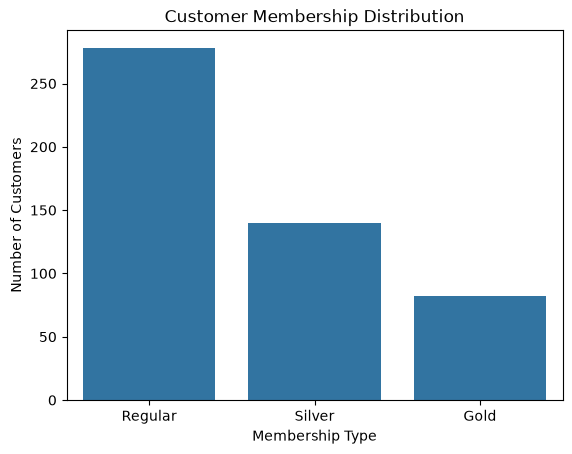

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=customers, x="membership")

plt.title("Customer Membership Distribution")
plt.xlabel("Membership Type")
plt.ylabel("Number of Customers")
plt.show()

In [9]:
customers["age"].describe()
customers["city"].value_counts()
customers["membership"].value_counts()

membership
Regular    278
Silver     140
Gold        82
Name: count, dtype: int64

In [10]:
# Average order value
orders["order_value"].describe()

count    2043.000000
mean     1559.860837
std      1009.319253
min        32.740000
25%       750.815000
50%      1430.300000
75%      2239.195000
max      5169.400000
Name: order_value, dtype: float64

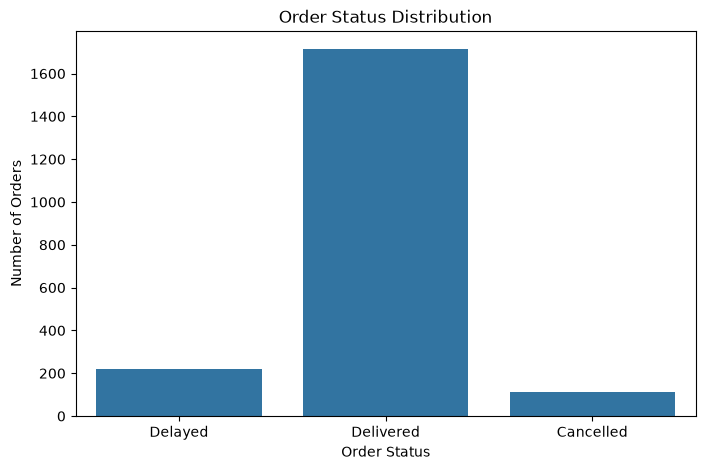

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(data=orders, x="order_status")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.show()

In [12]:
# Count each order status
status_counts = orders["order_status"].value_counts()

# Calculate percentages
status_percentage = orders["order_status"].value_counts(
    normalize=True
) * 100

print("ORDER COUNTS")
print(status_counts)

print("\nORDER STATUS PERCENTAGES")
print(status_percentage.round(2))

ORDER COUNTS
order_status
Delivered    1713
Delayed       219
Cancelled     111
Name: count, dtype: int64

ORDER STATUS PERCENTAGES
order_status
Delivered    83.85
Delayed      10.72
Cancelled     5.43
Name: proportion, dtype: float64


In [13]:
delivered_orders = orders[
    orders["order_status"] == "Delivered"
]

average_delivery_time = delivered_orders["delivery_minutes"].mean()

print("Average Delivery Time:", round(average_delivery_time, 2), "minutes")

Average Delivery Time: 25.04 minutes


In [14]:
# Merge order items and products
product_sales = order_items.merge(
    products,
    on="product_id",
    how="left"
)

display(product_sales.head())

,order_item_id,order_id,product_id,quantity,unit_price,product_name,category,price,stock_status
0,ITEM000001,ORD00001,PROD0035,3,165.82,Curd 35,Dairy,165.82,Low Stock
1,ITEM000002,ORD00001,PROD0054,3,418.41,Butter 54,Dairy,418.41,Out of Stock
2,ITEM000003,ORD00002,PROD0040,2,110.47,Chips 40,Snacks,110.47,In Stock
3,ITEM000004,ORD00002,PROD0004,2,41.20,Grapes 4,Fruits,41.20,In Stock
4,ITEM000005,ORD00003,PROD0030,2,441.51,Dishwash 30,Household,441.51,In Stock


In [15]:
# Calculate revenue for each product item
product_sales["revenue"] = (
    product_sales["quantity"] * product_sales["unit_price"]
)

# Find top 10 products by revenue
top_products = (
    product_sales.groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)


product_name
Curd 5             101249.55
Grapes 42           85838.72
Orange 45           82982.30
Soft Drink 55       82270.68
Potato 70           80094.17
Tissue Paper 57     79781.08
Curd 80             69367.76
Orange 32           69291.63
Orange 66           69154.98
Apple 41            68832.95
Name: revenue, dtype: float64

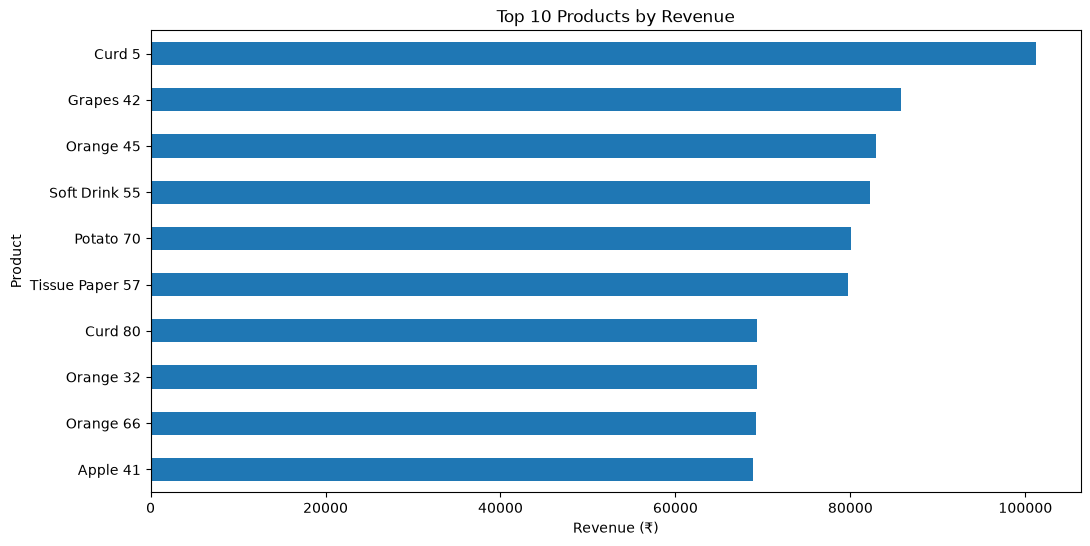

In [16]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")

plt.show()